In [282]:
import numpy as np
import matplotlib.pyplot as plt

In [283]:
def piecewise_quadratic_interpolation(x_data, y_data, x_interp):
  """
  Performs piecewise quadratic interpolation without overlapping subintervals.
  x_data (input): List or array of x values (must be sorted)
  y_data (input): List or array of corresponding y values
  x_interp (input): The x value where interpolation is needed
  return: Interpolated value at x_interp and piecewise quadratic polynomials
  """
  if len(x_data) < 3 or len(x_data)%2 == 0:
    raise ValueError("An odd number of points is required for non-overlapping quadratic interpolation.")
  if not np.all(np.diff(x_data) > 0):
    raise ValueError("x_data must be in strictly increasing order.")
  polynomials = []
  for i in range(0, len(x_data)-2, 2):
    x0, x1, x2 = x_data[i], x_data[i+1], x_data[i+2]
    y0, y1, y2 = y_data[i], y_data[i+1], y_data[i+2]
    # Solve for coefficients a, b, c in P(x) = ax^2+bx+c
    A = np.array([[x0**2, x0, 1], [x1**2, x1, 1], [x2**2, x2, 1]])
    B = np.array([y0, y1, y2])
    coeffs = np.linalg.solve(A, B)    # Solve linear systems
    a, b, c = coeffs
    polynomials.append((a, b, c, (x0, x2)))
  # Print all calculated polynomials
  print("Calculated Piecewise Quadratic Polynomials")
  for i, (a, b, c, (x0, x2)) in enumerate(polynomials):
    print(f"P{i}(x) = {a:.2f}x^2 + {b:.2f}x + {c:.2f}, for x in [{x0}, {x2}]")
  # Find the interval where x_interp falls
  y_interp = None
  for a, b, c, (x0, x2) in polynomials:
    if x0 <= x_interp <= x2:
      y_interp = a * x_interp**2 + b * x_interp + c
      break
  return y_interp, polynomials

In [284]:
def plot_interpolation(x_data, y_data, polynomials, x_interp=None, y_interp=None):
  """Plots the piecewise quadratic interpolation."""
  plt.figure(figsize=(8, 6))
  # Plot the piecewise quadratic segments
  for a, b, c, (x0, x2) in polynomials:
    x_vals = np.linspace(x0, x2, 100)
    y_vals = a * x_vals**2 + b * x_vals + c
    plt.plot(x_vals, y_vals, 'b-', label=f'P(x) = {a:.2f}x^2 + {b:.2f}x + {c:.2f}' if x0 == x_data[0] else '')
  # Scatter plot of given data points
  plt.scatter(x_data, y_data, color='red', label='Given Data Points')
  # Highlight interpolated point
  if x_interp is not None and y_interp is not None:
    plt.scatter(x_interp, y_interp, color='green', label=f'Interpolated Point ({x_interp:.2f}, {y_interp:.2f})', zorder=3)
  plt.xlabel('x')
  plt.ylabel('P(x)')
  plt.legend()
  plt.title('Piecewise Linear Interpolation')
  plt.grid()
  plt.show()

In [285]:
# Example Usage
# x_data = np.array([1, 2, 3, 4, 5])    # Given x points
# y_data = np.array([2, 4, 1, 3, 7])    # Given y points
x_data = np.array([-3, -2, -1, 1, 3, 6, 7])    # Given x points
y_data = np.array([369, 222, 171, 165, 207, 990, 1779])    # Given y points
x_interp = 6.5                        # Point to interpolate

In [286]:
y_interp, polynomials = piecewise_quadratic_interpolation(x_data, y_data, x_interp)
print(f'Interpolated value at x = {x_interp}: {y_interp}')

Calculated Piecewise Quadratic Polynomials
P0(x) = 48.00x^2 + 93.00x + 216.00, for x in [-3, -1]
P1(x) = 6.00x^2 + -3.00x + 162.00, for x in [-1, 3]
P2(x) = 132.00x^2 + -927.00x + 1800.00, for x in [3, 7]
Interpolated value at x = 6.5: 1351.4999999999998


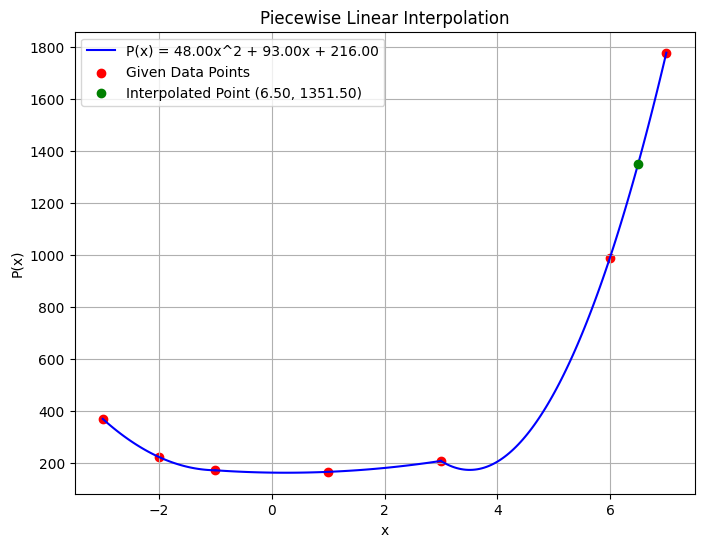

In [287]:
# Plot the interpolation
plot_interpolation(x_data, y_data, polynomials, x_interp, y_interp)